# Brain Tumor Classification from MRI Images Using Deep Learning and Image Processing Techniques

**Course:** ARTI 407 – Image Processing, Imam Abdulrahman bin Faisal University

**Team members:** Sarah Abdulrahman Al-Anzi (Leader), Haya Abdu Hakami, Danah Alhajri, Aseel AlQhtani, Rimas Alotaibi

**Dataset:** Brain Tumor MRI Dataset (Kaggle, Version 2) – https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
7,200 MRI images in 4 classes (glioma, meningioma, notumor, pituitary): 5,600 in `Training` and 1,600 in `Testing`.

**Pipeline:** exploration → image preprocessing (resize, median filter, CLAHE) → augmentation → three models (CNN from scratch, VGG16, ResNet50) → fine-tuning → evaluation on the untouched test set → error analysis and Grad-CAM.

**How to run:** Kaggle Notebook with the dataset attached, *Accelerator = GPU T4 x2* and *Internet = On* (needed to download the ImageNet weights). Run all cells from top to bottom (about 40 minutes). Results vary slightly between runs because GPU training is not fully deterministic.

## 1. Setup and dataset overview
Import the libraries, fix the random seed for reproducibility, and count the images per class in the training and testing folders.

In [1]:
# ===== Step 1: Setup and dataset overview =====
import os                                   # for working with folders and paths
import numpy as np                          # for numerical operations on arrays
import pandas as pd                         # for displaying results in a table
import matplotlib.pyplot as plt             # for plotting images and charts
import cv2                                  # OpenCV library for image processing
import tensorflow as tf                     # deep learning library

SEED = 42                                   # fixed number so results are reproducible
np.random.seed(SEED)                        # fix randomness in numpy
tf.random.set_seed(SEED)                    # fix randomness in tensorflow
OUT_DIR = "/kaggle/working"                      # folder where Kaggle keeps our output files (figures, weights, tables)

# Dataset path in Kaggle (taken from the output of the first cell)
BASE_DIR = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"
TRAIN_DIR = os.path.join(BASE_DIR, "Training")   # training folder
TEST_DIR = os.path.join(BASE_DIR, "Testing")     # testing folder

CLASSES = sorted(os.listdir(TRAIN_DIR))     # class names taken from the sub-folder names
print("Classes:", CLASSES)                  # print the class names

rows = []                                   # list to store the image count per class
for cls in CLASSES:                         # loop over each class
    n_train = len(os.listdir(os.path.join(TRAIN_DIR, cls)))  # number of training images
    n_test = len(os.listdir(os.path.join(TEST_DIR, cls)))    # number of testing images
    rows.append({"class": cls, "train": n_train, "test": n_test})  # store the counts

df = pd.DataFrame(rows)                     # convert the list to a table
df.loc["Total"] = ["-", df.train.sum(), df.test.sum()]  # add a totals row
print(df)                                   # display the table

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
            class  train  test
0          glioma   1400   400
1      meningioma   1400   400
2         notumor   1400   400
3       pituitary   1400   400
Total           -   5600  1600


## 2. Data exploration
Show random samples of each class and check the image sizes and channels. The sizes differ between images, so they must be unified before training.

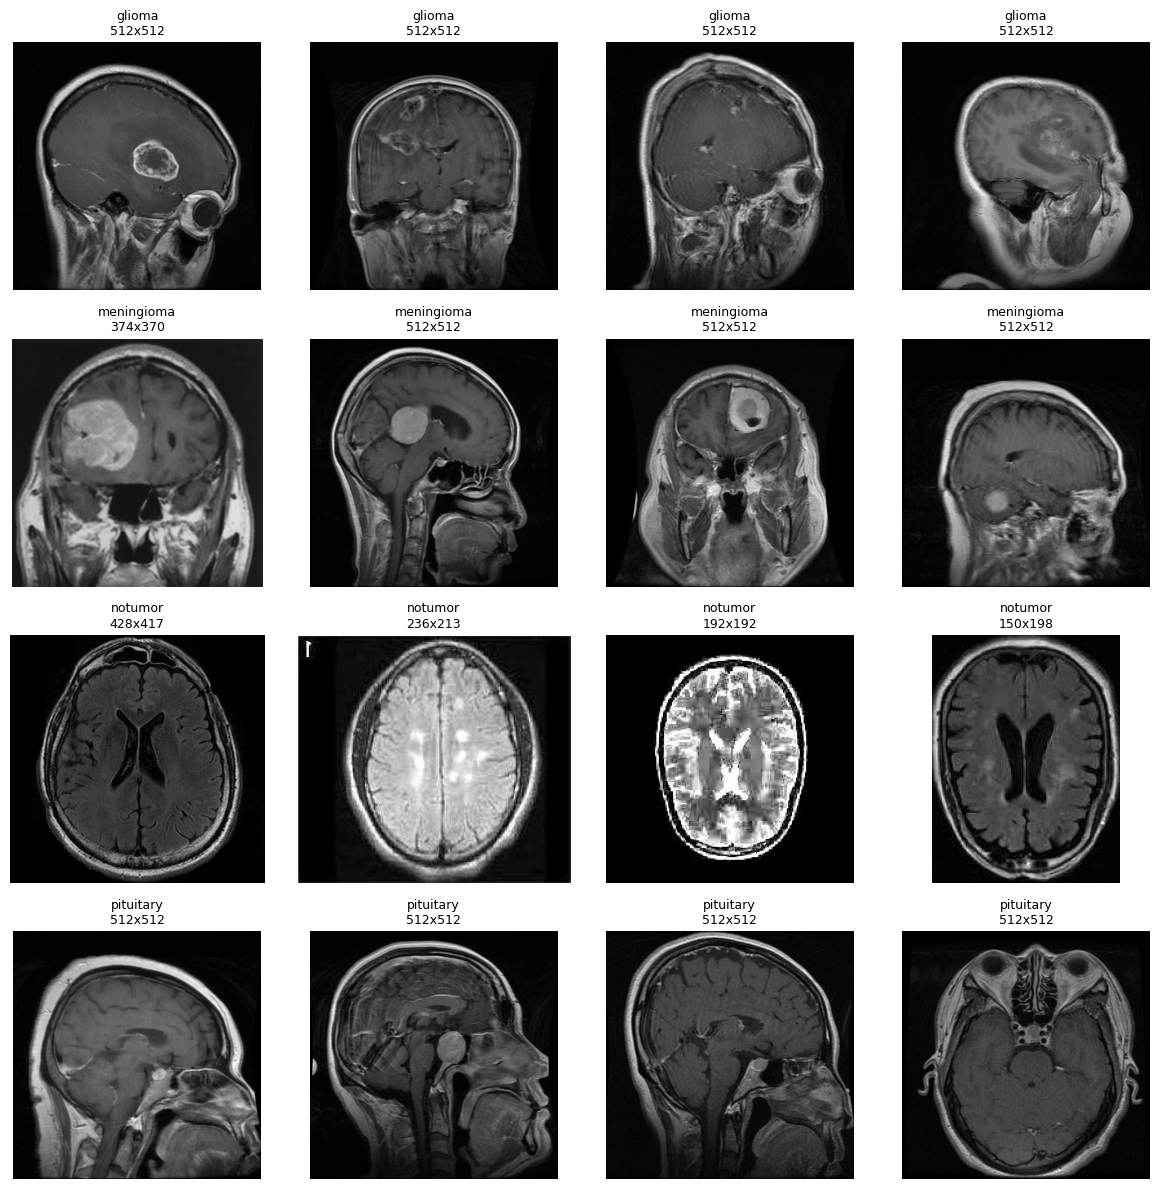

Number of different image shapes: 101
(512, 512, 3)    572
(225, 225, 3)     30
(630, 630, 3)      9
(251, 201, 3)      8
(442, 442, 3)      7
(234, 215, 3)      7
(217, 232, 3)      7
(250, 201, 3)      6
(221, 228, 3)      6
(417, 428, 3)      6
Name: count, dtype: int64


In [2]:
# ===== Step 2: Explore the data =====
import random                                    # for picking random images
random.seed(SEED)                                # fix the randomness for reproducibility

# --- Part A: show 4 random samples from each class ---
fig, axes = plt.subplots(4, 4, figsize=(12, 12)) # a 4x4 grid: one row per class
for i, cls in enumerate(CLASSES):                # loop over each class (row)
    folder = os.path.join(TRAIN_DIR, cls)        # folder of this class
    files = random.sample(os.listdir(folder), 4) # pick 4 random file names
    for j, fname in enumerate(files):            # loop over the 4 images (columns)
        img = cv2.imread(os.path.join(folder, fname))  # read the image (OpenCV loads BGR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)     # convert BGR to RGB for matplotlib
        axes[i][j].imshow(img)                   # draw the image
        axes[i][j].set_title(f"{cls}\n{img.shape[1]}x{img.shape[0]}", fontsize=9)  # class + width x height
        axes[i][j].axis("off")                   # hide the axes
plt.tight_layout()                               # fix the spacing between images
plt.savefig(f"{OUT_DIR}/fig_samples.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                       # display the figure

# --- Part B: check image sizes and channels on a sample ---
sizes = []                                       # list to store (height, width, channels)
for cls in CLASSES:                              # loop over each class
    folder = os.path.join(TRAIN_DIR, cls)        # folder of this class
    for fname in random.sample(os.listdir(folder), 200):  # 200 random images per class
        img = cv2.imread(os.path.join(folder, fname))     # read the image
        sizes.append(img.shape)                  # store its shape

size_counts = pd.Series(sizes).value_counts()    # count how often each shape appears
print("Number of different image shapes:", len(size_counts))  # how many different shapes
print(size_counts.head(10))                      # show the 10 most common shapes

## 3. Image preprocessing
Three techniques from the course are applied to every image:
1. **Resize to 224×224** (and grayscale conversion) – a unified input size for the networks.
2. **Median filter (3×3)** – removes noise while preserving the edges of the tumor.
3. **CLAHE** – improves the local contrast of soft tissue without amplifying noise as much as global histogram equalization.

The figure shows each step and the intensity histogram before and after.

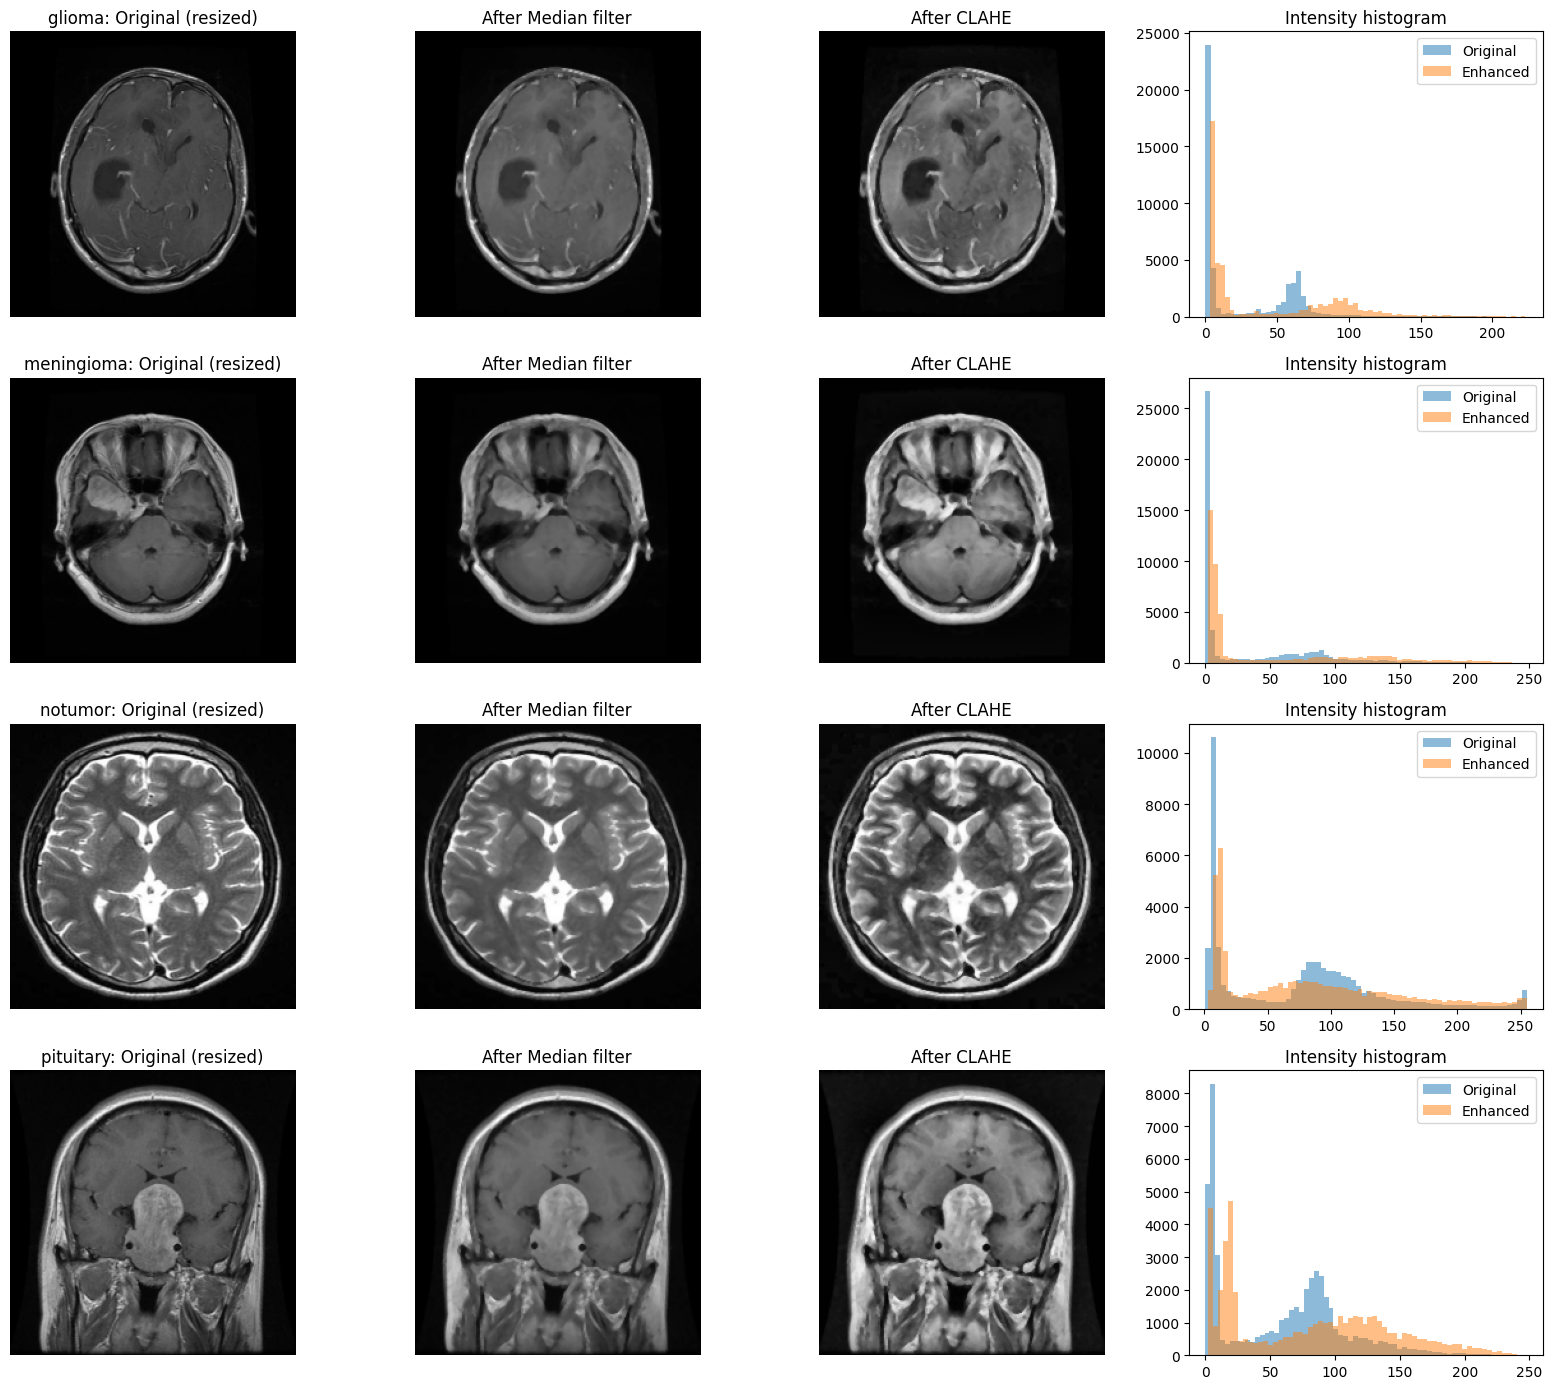

In [3]:
# ===== Step 3: Image preprocessing (Resize + Median filter + CLAHE) =====
IMG_SIZE = 224                                   # target size expected by VGG16 / ResNet50

def preprocess_image(img_bgr):
    """Apply the preprocessing pipeline and return each intermediate result."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)           # convert to grayscale (MRI is single-channel)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE),
                      interpolation=cv2.INTER_AREA)            # resize to 224x224 (INTER_AREA is good for shrinking)
    denoised = cv2.medianBlur(gray, 3)                         # median filter 3x3 to reduce noise and keep edges
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))  # CLAHE: local contrast enhancement
    enhanced = clahe.apply(denoised)                           # apply CLAHE on the denoised image
    return gray, denoised, enhanced                            # return all three stages

# --- Visualize the effect of each step (one random image per class) ---
fig, axes = plt.subplots(4, 4, figsize=(16, 14))               # 4 classes (rows) x 4 views (columns)
for i, cls in enumerate(CLASSES):                              # loop over each class
    folder = os.path.join(TRAIN_DIR, cls)                      # folder of this class
    fname = random.choice(os.listdir(folder))                  # pick one random image
    img = cv2.imread(os.path.join(folder, fname))              # read the image
    gray, denoised, enhanced = preprocess_image(img)           # run the pipeline

    axes[i][0].imshow(gray, cmap="gray")                       # original (resized, grayscale)
    axes[i][0].set_title(f"{cls}: Original (resized)")         # title
    axes[i][1].imshow(denoised, cmap="gray")                   # after median filter
    axes[i][1].set_title("After Median filter")                # title
    axes[i][2].imshow(enhanced, cmap="gray")                   # after CLAHE
    axes[i][2].set_title("After CLAHE")                        # title
    axes[i][3].hist(gray.ravel(), bins=64, alpha=0.5, label="Original")    # histogram before
    axes[i][3].hist(enhanced.ravel(), bins=64, alpha=0.5, label="Enhanced") # histogram after
    axes[i][3].set_title("Intensity histogram")                # title
    axes[i][3].legend()                                        # show legend
    for k in range(3):                                         # hide axes of the three image columns
        axes[i][k].axis("off")                                 # hide axes
plt.tight_layout()                                             # fix spacing
plt.savefig(f"{OUT_DIR}/fig_preprocessing.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                                     # display the figure

## 4. Loading the preprocessed images and splitting the data
The `Training` folder is split into 80% training and 20% validation (stratified, so the classes stay balanced). The `Testing` folder is used only for the final evaluation.

In [4]:
# ===== Step 4: Load preprocessed images and split the data =====
from sklearn.model_selection import train_test_split   # for the stratified train/validation split

def load_split(base_dir):
    """Read every image in base_dir, preprocess it, and return arrays of images and labels."""
    images, labels = [], []                                # lists to collect images and labels
    for idx, cls in enumerate(CLASSES):                    # loop over classes (idx = numeric label)
        folder = os.path.join(base_dir, cls)               # folder of this class
        for fname in sorted(os.listdir(folder)):           # loop over all files in the folder
            img = cv2.imread(os.path.join(folder, fname))  # read the image
            if img is None:                                # skip files that cannot be read
                continue                                   # go to the next file
            _, _, enhanced = preprocess_image(img)         # keep only the final result (resize + median + CLAHE)
            images.append(enhanced)                        # store the processed image
            labels.append(idx)                             # store its numeric label
    return np.array(images, dtype=np.uint8), np.array(labels)  # convert lists to numpy arrays

X_trainval, y_trainval = load_split(TRAIN_DIR)             # load all training-folder images
X_test, y_test = load_split(TEST_DIR)                      # load all testing-folder images (kept for final evaluation)

# Split the training folder into train (80%) and validation (20%), keeping class balance
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,                                # data to split
    test_size=0.2,                                         # 20% goes to validation
    stratify=y_trainval,                                   # keep the same class proportions in both parts
    random_state=SEED)                                     # reproducible split

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)  # print the array shapes
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:          # check class balance per split
    print(name, np.bincount(y))                            # number of images per class

Train: (4480, 224, 224) | Val: (1120, 224, 224) | Test: (1600, 224, 224)
train [1120 1120 1120 1120]
val [280 280 280 280]
test [400 400 400 400]


## 5. Data augmentation and input pipeline
Random flip, rotation (about ±14°), translation (5%) and zoom (10%) are applied to the **training images only**, to reduce overfitting. The black background is kept with `fill_mode="constant"`.

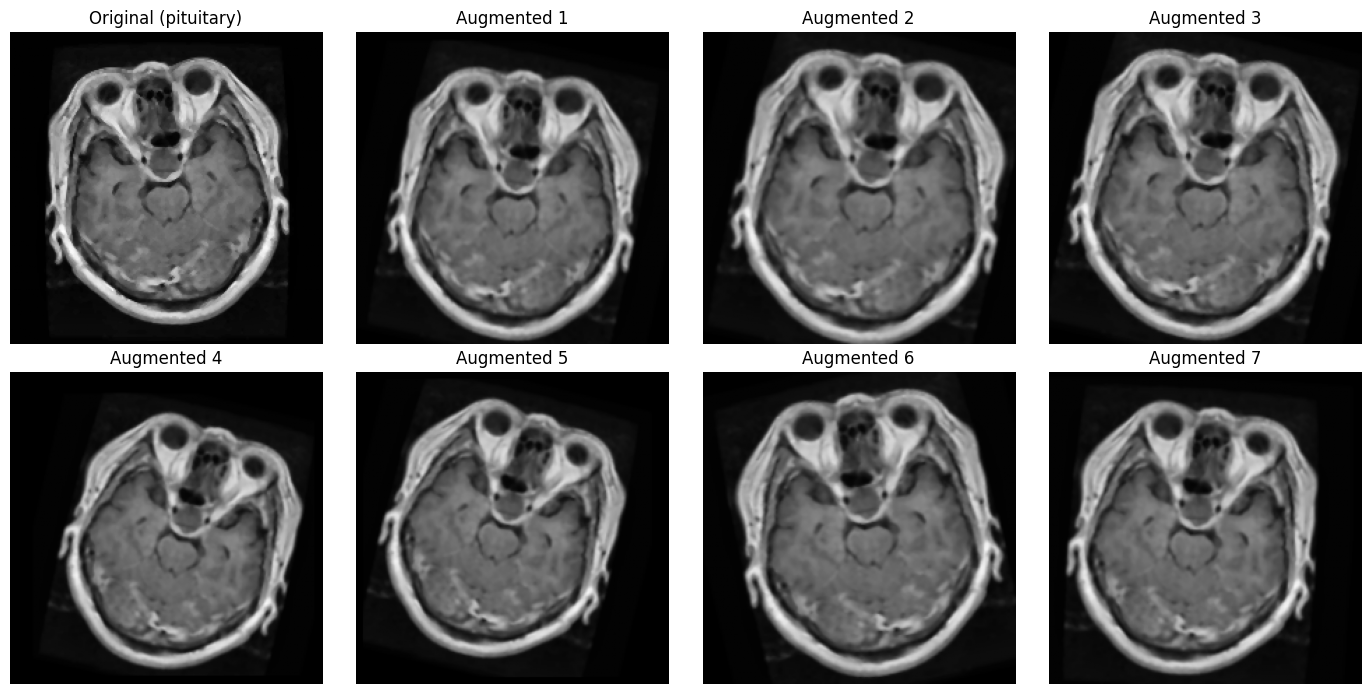

Batch images: (32, 224, 224, 3) | Batch labels: (32,)
Pixel range: 0.0 - 255.0


In [5]:
# ===== Step 5: Data augmentation and input pipeline =====
BATCH_SIZE = 32                                          # number of images per training step
AUTOTUNE = tf.data.AUTOTUNE                              # let tensorflow choose the parallelism level

# Augmentation layers (geometric transformations, applied to training images only)
augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),            # random left-right flip
    tf.keras.layers.RandomRotation(0.04, fill_mode="constant", fill_value=0.0),          # rotate up to about +-14 degrees
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0), # shift up to 5% in x and y
    tf.keras.layers.RandomZoom(0.1, fill_mode="constant", fill_value=0.0),               # zoom in/out up to 10%
], name="augmentation")                                  # name of the augmentation block

def make_dataset(X, y, training):
    """Build a batched tf.data pipeline. Augmentation is applied only when training=True."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))      # create a dataset from the numpy arrays
    if training:                                         # shuffle only the training data
        ds = ds.shuffle(len(X), seed=SEED)               # random order of images each epoch
    ds = ds.batch(BATCH_SIZE)                            # group images into batches

    def prep(images, labels):
        images = tf.cast(images, tf.float32)[..., tf.newaxis]   # to float32 and add a channel dimension
        if training:                                     # augmentation for training data only
            images = augmenter(images, training=True)    # apply the random transformations
        images = tf.image.grayscale_to_rgb(images)       # repeat to 3 channels (pretrained models need RGB)
        return images, labels                            # pixel values stay in 0-255 for now

    return ds.map(prep, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)  # apply prep and prefetch batches

train_ds = make_dataset(X_train, y_train, training=True)   # training pipeline (with augmentation)
val_ds = make_dataset(X_val, y_val, training=False)        # validation pipeline (no augmentation)
test_ds = make_dataset(X_test, y_test, training=False)     # test pipeline (no augmentation)

# --- Preview: one original image and 7 augmented versions of it ---
idx = random.randrange(len(X_train))                       # pick a random training image
sample = X_train[idx]                                      # the chosen image
fig, axes = plt.subplots(2, 4, figsize=(14, 7))            # 2x4 grid
axes = axes.ravel()                                        # flatten the grid to a list
axes[0].imshow(sample, cmap="gray")                        # show the original in the first cell
axes[0].set_title(f"Original ({CLASSES[y_train[idx]]})")   # title with the class name
for k in range(1, 8):                                      # 7 augmented versions
    aug = augmenter(sample[np.newaxis, ..., np.newaxis].astype("float32"), training=True)  # augment one image
    axes[k].imshow(aug[0, ..., 0], cmap="gray", vmin=0, vmax=255)  # show the augmented image
    axes[k].set_title(f"Augmented {k}")                    # title
for ax in axes:                                            # hide the axes
    ax.axis("off")                                         # hide axes
plt.tight_layout()                                         # fix spacing
plt.savefig(f"{OUT_DIR}/fig_augmentation.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                                 # display the figure

for images, labels in train_ds.take(1):                    # take one batch to check the shapes
    print("Batch images:", images.shape, "| Batch labels:", labels.shape)  # print the shapes
    print("Pixel range:", float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))  # min and max pixel values

## 6. Building the three models
1. **CNN from scratch** – four convolution blocks; used as a baseline.
2. **VGG16** (transfer learning) – ImageNet weights, frozen backbone and a new classifier head.
3. **ResNet50** (transfer learning) – same idea with a residual network.

In [6]:
# ===== Step 6: Build the three models =====
from tensorflow.keras import layers, models                 # building blocks for the models
from tensorflow.keras.applications import VGG16, ResNet50   # pretrained architectures
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_prep      # VGG16 input scaling
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_prep  # ResNet50 input scaling

print("GPUs available:", tf.config.list_physical_devices("GPU"))  # check if a GPU is available

INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)                        # model input: 224x224 RGB
NUM_CLASSES = len(CLASSES)                                   # 4 output classes

# ---------- Model 1: CNN from scratch ----------
def build_cnn():
    inputs = layers.Input(shape=INPUT_SHAPE)                 # input layer
    x = layers.Rescaling(1.0 / 255)(inputs)                 # scale pixels from 0-255 to 0-1
    for filters in [32, 64, 128, 256]:                       # four convolution blocks
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)  # convolution + ReLU
        x = layers.BatchNormalization()(x)                   # stabilize and speed up training
        x = layers.MaxPooling2D()(x)                         # halve the spatial size
    x = layers.GlobalAveragePooling2D()(x)                   # one value per feature map
    x = layers.Dropout(0.4)(x)                               # dropout to reduce overfitting
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)  # class probabilities
    return models.Model(inputs, outputs, name="CNN_scratch") # build the model

# ---------- Models 2 and 3: transfer learning ----------
def build_transfer(base_cls, prep_fn, name):
    base = base_cls(weights="imagenet", include_top=False, input_shape=INPUT_SHAPE)  # pretrained backbone
    base.trainable = False                                   # freeze the pretrained layers at first
    inputs = layers.Input(shape=INPUT_SHAPE)                 # input layer
    x = layers.Lambda(prep_fn)(inputs)                       # apply the scaling this backbone expects
    x = base(x, training=False)                              # extract features with the frozen backbone
    x = layers.GlobalAveragePooling2D()(x)                   # one value per feature map
    x = layers.Dense(256, activation="relu")(x)              # our own dense layer
    x = layers.Dropout(0.5)(x)                               # dropout to reduce overfitting
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)  # class probabilities
    return models.Model(inputs, outputs, name=name)          # build the model

model_cnn = build_cnn()                                      # create model 1
model_vgg = build_transfer(VGG16, vgg_prep, "VGG16_transfer")          # create model 2
model_resnet = build_transfer(ResNet50, resnet_prep, "ResNet50_transfer")  # create model 3

for m, lr in [(model_cnn, 1e-3), (model_vgg, 1e-4), (model_resnet, 1e-4)]:  # compile each model
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),        # Adam optimizer (smaller lr for transfer models)
              loss="sparse_categorical_crossentropy",        # loss for integer class labels
              metrics=["accuracy"])                          # track accuracy during training

summary = pd.DataFrame([{                                    # compare the three models in one table
    "model": m.name,                                         # model name
    "total_params": m.count_params(),                        # all parameters
    "trainable_params": int(sum(np.prod(w.shape) for w in m.trainable_weights)),  # parameters that will be trained
} for m in [model_cnn, model_vgg, model_resnet]])
print(summary)                                               # display the table

GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
               model  total_params  trainable_params
0        CNN_scratch        391364            390404
1     VGG16_transfer      14847044            132356
2  ResNet50_transfer      24113284            525572


## 7. Training model 1 (CNN from scratch)
Training uses early stopping, learning-rate reduction on plateau, and saves the best weights (by validation accuracy).

In [7]:
# ===== Step 7: Train model 1 (CNN from scratch) =====
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint  # training helpers

histories = {}                                           # dictionary to store the training history of each model

def train_model(model, name, epochs):
    """Train a model with early stopping, learning-rate reduction and best-weights saving."""
    callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=5,
                      restore_best_weights=True),        # stop if val accuracy does not improve for 5 epochs
        ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                          patience=2, min_lr=1e-6),      # halve the learning rate when val loss stops improving
        ModelCheckpoint(f"{OUT_DIR}/{name}.weights.h5",
                        monitor="val_accuracy",
                        save_best_only=True,
                        save_weights_only=True),         # save only the best weights to disk
    ]
    hist = model.fit(train_ds,                           # training data (with augmentation)
                     validation_data=val_ds,             # validation data (no augmentation)
                     epochs=epochs,                      # maximum number of epochs
                     callbacks=callbacks,                # the helpers defined above
                     verbose=1)                          # print progress for each epoch
    histories[name] = hist.history                       # keep the history in memory
    pd.DataFrame(hist.history).to_csv(f"{OUT_DIR}/{name}_history.csv", index=False)  # save the history to a file
    return hist                                          # return the history object

train_model(model_cnn, "CNN_scratch", epochs=25)         # train the CNN (up to 25 epochs)

Epoch 1/25


E0000 00:00:1794809796.020005      76 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 94ms/step - accuracy: 0.7107 - loss: 0.7484 - val_accuracy: 0.2732 - val_loss: 4.6548 - learning_rate: 0.0010
Epoch 2/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.7772 - loss: 0.5948 - val_accuracy: 0.2741 - val_loss: 5.4578 - learning_rate: 0.0010
Epoch 3/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.7987 - loss: 0.5375 - val_accuracy: 0.3607 - val_loss: 3.7117 - learning_rate: 0.0010
Epoch 4/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8266 - loss: 0.4649 - val_accuracy: 0.6786 - val_loss: 0.8151 - learning_rate: 0.0010
Epoch 5/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8272 - loss: 0.4563 - val_accuracy: 0.7580 - val_loss: 0.7149 - learning_rate: 0.0010
Epoch 6/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8420 - loss: 0.4273 - val_accuracy: 0.6839 - val_loss: 0.8655 - learning_rate: 0.0010
Epoch 7/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8567 - loss: 0.3895

## 8. Training model 2 (VGG16) and model 3 (ResNet50)
Only the new classifier head is trained here; the pretrained backbone is frozen.

In [8]:
# ===== Step 8: Train model 2 (VGG16) and model 3 (ResNet50) =====
train_model(model_vgg, "VGG16_transfer", epochs=15)        # train VGG16 with the frozen pretrained backbone
train_model(model_resnet, "ResNet50_transfer", epochs=15)  # train ResNet50 with the frozen pretrained backbone

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 181ms/step - accuracy: 0.4299 - loss: 2.4840 - val_accuracy: 0.6938 - val_loss: 0.8797 - learning_rate: 1.0000e-04
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 175ms/step - accuracy: 0.6527 - loss: 1.0846 - val_accuracy: 0.7875 - val_loss: 0.6054 - learning_rate: 1.0000e-04
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 174ms/step - accuracy: 0.7208 - loss: 0.8103 - val_accuracy: 0.8152 - val_loss: 0.4992 - learning_rate: 1.0000e-04
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 175ms/step - accuracy: 0.7460 - loss: 0.6855 - val_accuracy: 0.8286 - val_loss: 0.4609 - learning_rate: 1.0000e-04
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 175ms/step - accuracy: 0.7808 - loss: 0.5962 - val_accuracy: 0.8527 - val_loss: 0.4209 - learning_rate: 1.0000e-04
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 173ms/step - accuracy: 0.7875 - loss: 0.5754 - val_accuracy: 0.8429 - val_loss: 0.4111 - learning_rate: 1.0000e-04
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 17

## 9. Evaluation of the three models on the test set
Accuracy, macro precision / recall / F1, per-class report and confusion matrix (rows = true class, columns = predicted class), plus the training curves.

===== CNN_scratch =====
              precision    recall  f1-score   support

      glioma     0.9863    0.7200    0.8324       400
  meningioma     0.8118    0.8625    0.8364       400
     notumor     0.8110    0.9975    0.8946       400
   pituitary     0.9668    0.9450    0.9558       400

    accuracy                         0.8812      1600
   macro avg     0.8939    0.8812    0.8798      1600
weighted avg     0.8939    0.8812    0.8798      1600

===== VGG16_transfer =====
              precision    recall  f1-score   support

      glioma     0.9179    0.6150    0.7365       400
  meningioma     0.7366    0.7200    0.7282       400
     notumor     0.8550    0.9875    0.9165       400
   pituitary     0.8038    0.9625    0.8760       400

    accuracy                         0.8213      1600
   macro avg     0.8283    0.8212    0.8143      1600
weighted avg     0.8283    0.8213    0.8143      1600

===== ResNet50_transfer =====
              precision    recall  f1-score   sup

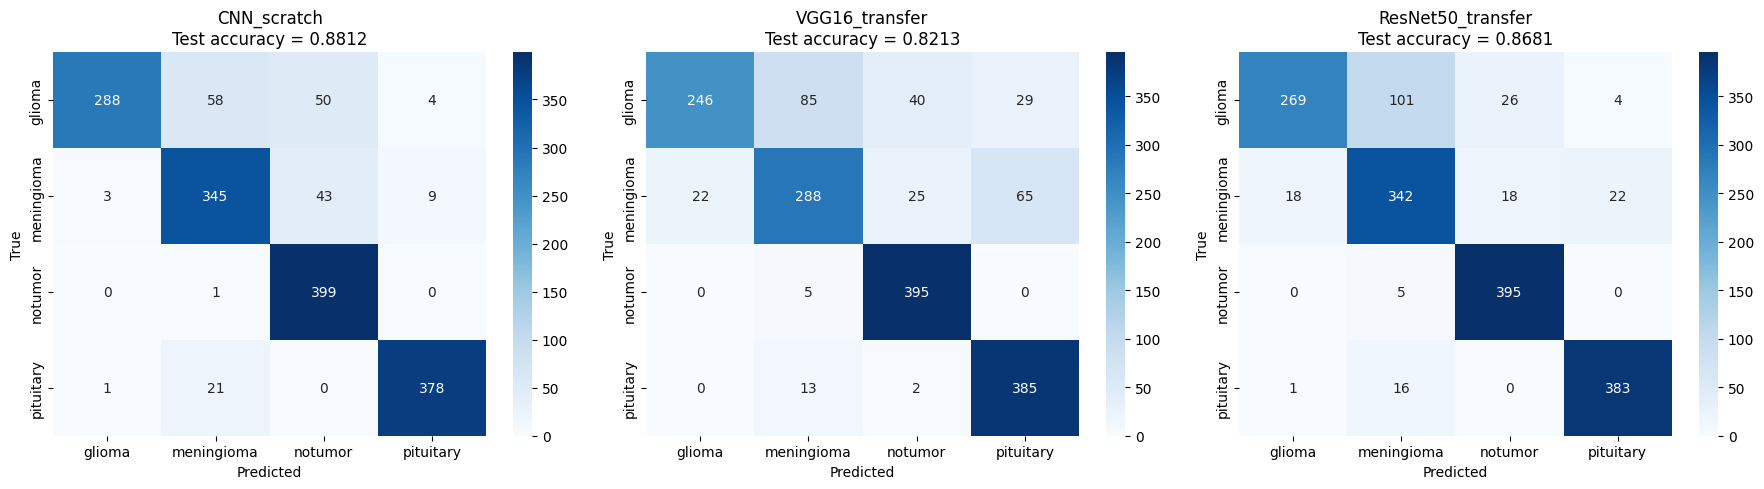

               model  accuracy  precision  recall  f1_score
0        CNN_scratch    0.8812     0.8939  0.8812    0.8798
1     VGG16_transfer    0.8212     0.8283  0.8212    0.8143
2  ResNet50_transfer    0.8681     0.8768  0.8681    0.8655


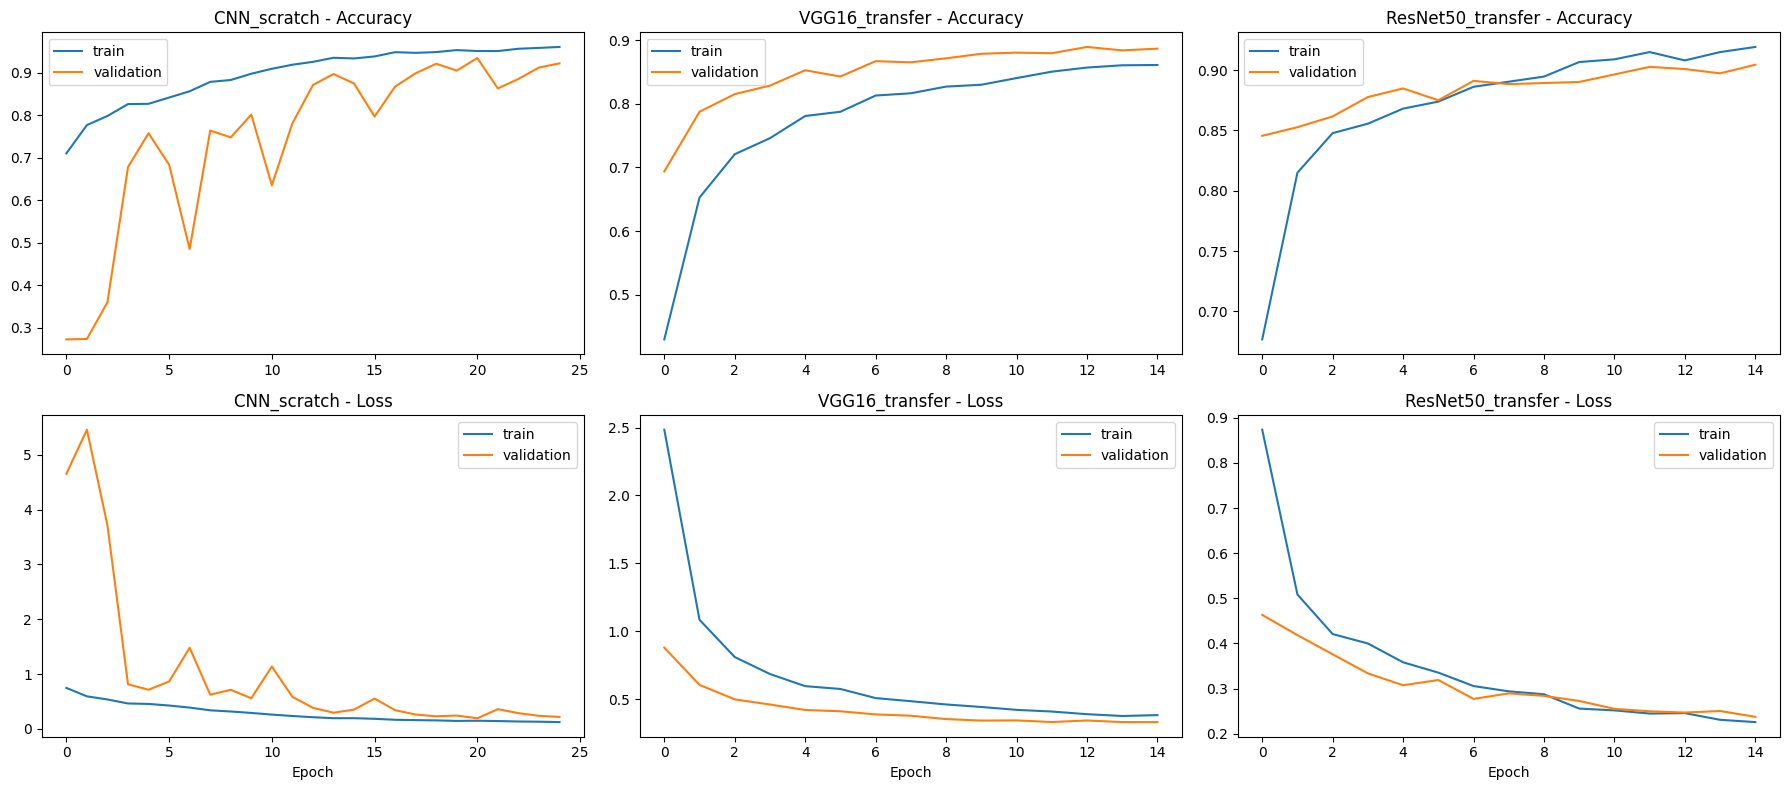

In [9]:
# ===== Step 9: Evaluate the three models on the test set =====
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)  # evaluation metrics
import seaborn as sns                                    # for drawing the confusion matrices

models_dict = {                                          # the three trained models
    "CNN_scratch": model_cnn,
    "VGG16_transfer": model_vgg,
    "ResNet50_transfer": model_resnet,
}
results = []                                             # list to collect the metrics of each model
predictions = {}                                         # dictionary to keep each model's predictions

fig, axes = plt.subplots(1, 3, figsize=(18, 5))          # one confusion matrix per model
for ax, (name, model) in zip(axes, models_dict.items()): # loop over the three models
    model.load_weights(f"{OUT_DIR}/{name}.weights.h5")   # load the best saved weights
    probs = model.predict(test_ds, verbose=0)            # predicted probabilities for the test images
    y_pred = np.argmax(probs, axis=1)                    # the class with the highest probability
    predictions[name] = y_pred                           # store the predictions

    acc = accuracy_score(y_test, y_pred)                 # overall accuracy
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")  # macro-averaged metrics
    results.append({"model": name, "accuracy": acc,
                    "precision": p, "recall": r, "f1_score": f1})  # store the metrics

    print(f"===== {name} =====")                         # model name
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))  # per-class report

    cm = confusion_matrix(y_test, y_pred)                # confusion matrix (rows = true, columns = predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)  # draw it as a heatmap
    ax.set_title(f"{name}\nTest accuracy = {acc:.4f}")   # title with the accuracy
    ax.set_xlabel("Predicted")                           # x-axis label
    ax.set_ylabel("True")                                # y-axis label
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_confusion_frozen.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the confusion matrices

results_df = pd.DataFrame(results).round(4)              # comparison table of the three models
print(results_df)                                        # display the table

# --- Training curves (accuracy and loss) of the three models ---
fig, axes = plt.subplots(2, 3, figsize=(18, 8))          # top row: accuracy, bottom row: loss
for col, name in enumerate(models_dict):                 # one column per model
    h = histories[name]                                  # the training history of this model
    axes[0][col].plot(h["accuracy"], label="train")      # training accuracy
    axes[0][col].plot(h["val_accuracy"], label="validation")  # validation accuracy
    axes[0][col].set_title(f"{name} - Accuracy")         # title
    axes[0][col].legend()                                # show legend
    axes[1][col].plot(h["loss"], label="train")          # training loss
    axes[1][col].plot(h["val_loss"], label="validation") # validation loss
    axes[1][col].set_title(f"{name} - Loss")             # title
    axes[1][col].legend()                                # show legend
    axes[1][col].set_xlabel("Epoch")                     # x-axis label
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_curves_frozen.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the curves

## 10. Fine-tuning VGG16 and ResNet50
The last convolutional block is unfrozen (BatchNorm layers stay frozen) and trained with a very small learning rate (1e-5). The new weights are saved under new names, so the frozen-backbone results are kept for comparison.

In [10]:
# ===== Step 10: Fine-tune the last block of VGG16 and ResNet50 =====
def unfreeze_top(model, base_name, prefix):
    """Unfreeze only the layers of the last block of the backbone (BatchNorm layers stay frozen)."""
    base = model.get_layer(base_name)                    # the pretrained backbone inside our model
    base.trainable = True                                # make the backbone trainable
    for layer in base.layers:                            # loop over the backbone layers
        is_bn = isinstance(layer, layers.BatchNormalization)         # check if the layer is BatchNorm
        layer.trainable = layer.name.startswith(prefix) and not is_bn  # train only the last block (not BatchNorm)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),  # very small learning rate for fine-tuning
                  loss="sparse_categorical_crossentropy",    # same loss as before
                  metrics=["accuracy"])                      # same metric as before (must recompile after changing trainable)
    n_train = int(sum(np.prod(w.shape) for w in model.trainable_weights))  # number of trainable parameters now
    print(f"{model.name}: trainable parameters = {n_train:,}")   # print it

unfreeze_top(model_vgg, "vgg16", "block5_")              # VGG16: unfreeze block 5
unfreeze_top(model_resnet, "resnet50", "conv5_")         # ResNet50: unfreeze stage 5

train_model(model_vgg, "VGG16_finetuned", epochs=15)       # continue training VGG16
train_model(model_resnet, "ResNet50_finetuned", epochs=15) # continue training ResNet50

# --- Evaluate the fine-tuned models on the test set ---
for name, model in [("VGG16_finetuned", model_vgg), ("ResNet50_finetuned", model_resnet)]:  # loop over both
    model.load_weights(f"{OUT_DIR}/{name}.weights.h5")   # load the best weights of this stage
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)  # predicted classes
    predictions[name] = y_pred                           # store the predictions
    print(f"===== {name} =====")                         # model name
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))  # per-class report
    print(confusion_matrix(y_test, y_pred))              # confusion matrix as numbers

VGG16_transfer: trainable parameters = 7,211,780
ResNet50_transfer: trainable parameters = 15,479,044
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 210ms/step - accuracy: 0.8663 - loss: 0.3600 - val_accuracy: 0.8830 - val_loss: 0.3086 - learning_rate: 1.0000e-05
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.8911 - loss: 0.2942 - val_accuracy: 0.9080 - val_loss: 0.2679 - learning_rate: 1.0000e-05
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.9134 - loss: 0.2413 - val_accuracy: 0.9196 - val_loss: 0.2196 - learning_rate: 1.0000e-05
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.9239 - loss: 0.2124 - val_accuracy: 0.9232 - val_loss: 0.2212 - learning_rate: 1.0000e-05
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.9335 - loss: 0.1783 - val_accuracy: 0.9259 - val_loss: 0.2107 - learning_rate: 1.0000e-05
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 198ms/step - accuracy: 0.9388 - loss: 0.1611 - val_accuracy

## 11. Final comparison and error analysis
Comparison table of the five models (saved as `model_comparison.csv`), a bar chart, and examples of glioma images misclassified by the best model.

             model  accuracy  precision  recall  f1_score  tumors_missed_as_notumor
   VGG16_finetuned    0.9256     0.9298  0.9256    0.9237                        39
ResNet50_finetuned    0.9250     0.9326  0.9250    0.9231                        22
       CNN_scratch    0.8812     0.8939  0.8812    0.8798                        93
 ResNet50_transfer    0.8681     0.8768  0.8681    0.8655                        44
    VGG16_transfer    0.8212     0.8283  0.8212    0.8143                        67


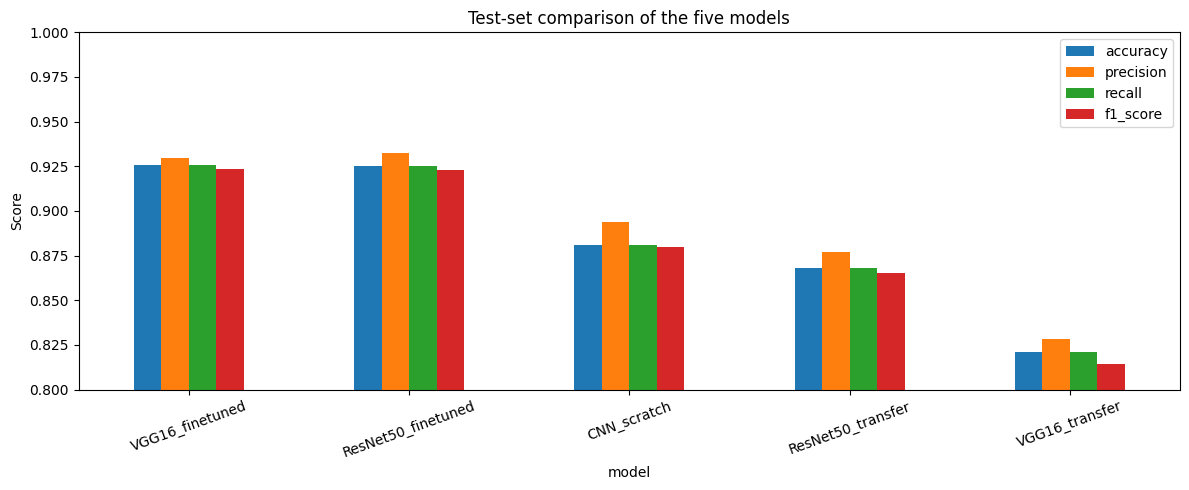

VGG16_finetuned: 91 glioma images were misclassified


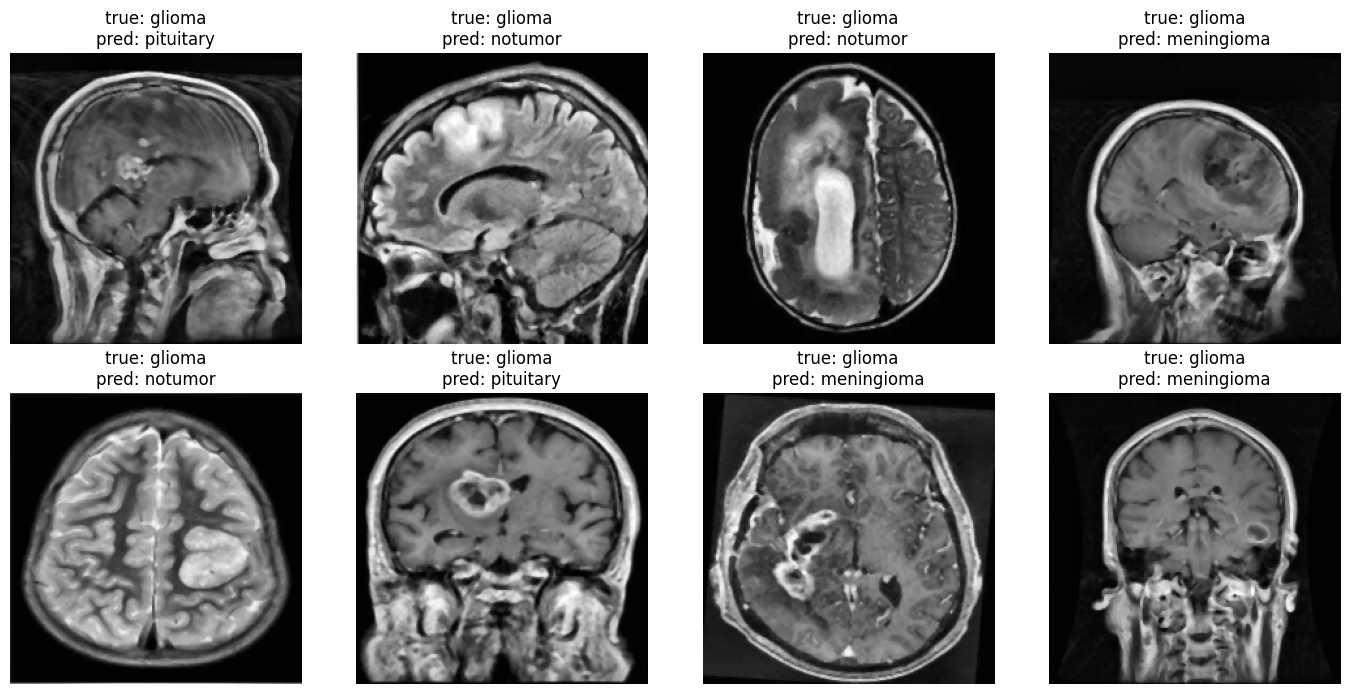

In [11]:
# ===== Step 11: Final comparison and error analysis =====
notumor_idx = CLASSES.index("notumor")                   # numeric label of the "notumor" class

rows = []                                                # list to collect the metrics of every model
for name, y_pred in predictions.items():                 # loop over all evaluated models
    acc = accuracy_score(y_test, y_pred)                 # overall accuracy
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")  # macro metrics
    missed = int(np.sum((y_test != notumor_idx) & (y_pred == notumor_idx)))  # tumors predicted as "no tumor"
    rows.append({"model": name, "accuracy": acc, "precision": p,
                 "recall": r, "f1_score": f1, "tumors_missed_as_notumor": missed})  # store the results

comparison = pd.DataFrame(rows).round(4).sort_values("f1_score", ascending=False)  # sort by F1 (best first)
comparison.to_csv(f"{OUT_DIR}/model_comparison.csv", index=False)  # save the table for the report
print(comparison.to_string(index=False))                 # display the table

# --- Bar chart comparing the models ---
ax = comparison.set_index("model")[["accuracy", "precision", "recall", "f1_score"]].plot(
    kind="bar", figsize=(12, 5))                         # grouped bars: one group per model
ax.set_ylim(0.8, 1.0)                                    # zoom the y-axis to see the differences
ax.set_title("Test-set comparison of the five models")   # title
ax.set_ylabel("Score")                                   # y-axis label
plt.xticks(rotation=20)                                  # rotate model names for readability
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_comparison.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the chart

# --- Error analysis: glioma images misclassified by the best model ---
best = comparison.iloc[0]["model"]                       # name of the best model (highest F1)
glioma_idx = CLASSES.index("glioma")                     # numeric label of glioma
wrong = np.where((y_test == glioma_idx) & (predictions[best] != glioma_idx))[0]  # indices of misclassified glioma
print(f"{best}: {len(wrong)} glioma images were misclassified")  # how many
random.seed(SEED)                                        # reproducible random choice
chosen = random.sample(list(wrong), 8)                   # pick 8 examples to display

fig, axes = plt.subplots(2, 4, figsize=(14, 7))          # 2x4 grid
for ax, i in zip(axes.ravel(), chosen):                  # loop over the chosen examples
    ax.imshow(X_test[i], cmap="gray")                    # show the preprocessed image
    ax.set_title(f"true: glioma\npred: {CLASSES[predictions[best][i]]}")  # true vs predicted class
    ax.axis("off")                                       # hide the axes
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_errors.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the figure

## 12. Grad-CAM for the best model
Heatmaps show which regions of the image influenced the prediction (red = strong influence). Top row: correct predictions; bottom row: misclassified glioma images.

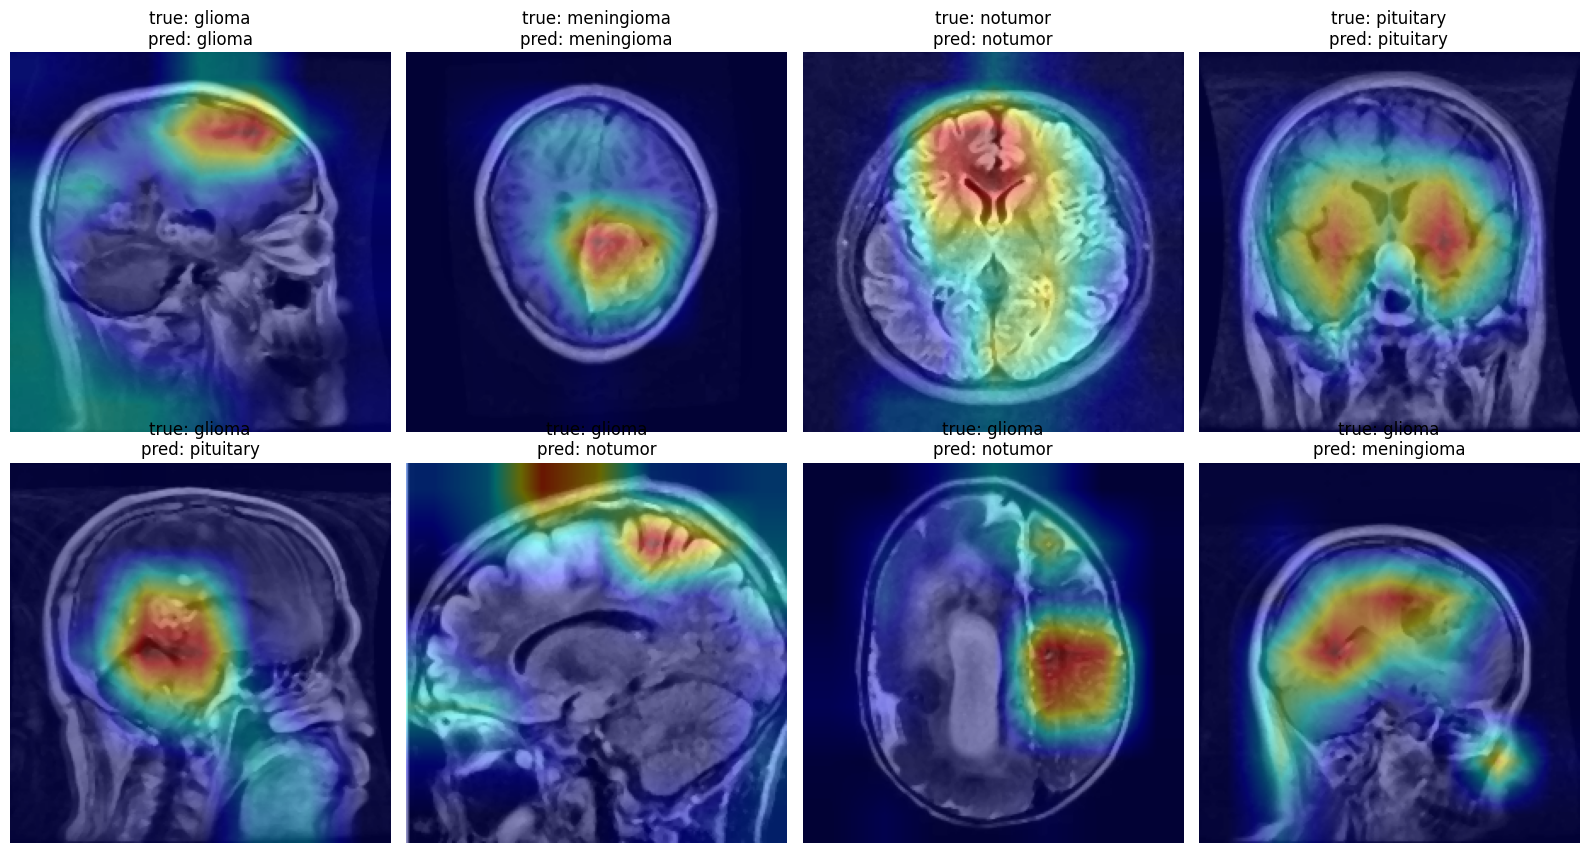

In [12]:
# ===== Step 12: Grad-CAM for the best model (VGG16 fine-tuned) =====
def make_gradcam_models(model, base_name):
    """Split the model into (input -> last conv feature maps) and (feature maps -> prediction)."""
    names = [l.name for l in model.layers]               # names of all layers in the model
    k = names.index(base_name)                           # position of the pretrained backbone
    x = inp = model.input                                # start from the model input
    for layer in model.layers[1:k + 1]:                  # pass through the layers up to the backbone
        x = layer(x)                                     # apply the layer
    feat_model = tf.keras.Model(inp, x)                  # model that outputs the last convolutional feature maps
    h = hin = tf.keras.Input(shape=x.shape[1:])          # new input = the feature maps
    for layer in model.layers[k + 1:]:                   # pass through the remaining layers (the classifier head)
        h = layer(h)                                     # apply the layer
    head_model = tf.keras.Model(hin, h)                  # model that turns feature maps into class probabilities
    return feat_model, head_model                        # return both parts

def to_input(img):
    """Convert one stored grayscale image (224x224) to a model-ready batch of shape (1,224,224,3)."""
    t = tf.cast(img, tf.float32)[tf.newaxis, ..., tf.newaxis]  # add batch and channel dimensions
    return tf.image.grayscale_to_rgb(t)                  # repeat to 3 channels

def gradcam(feat_model, head_model, img):
    """Return a heatmap (0-1) showing which regions support the predicted class."""
    feat = feat_model(to_input(img), training=False)     # last convolutional feature maps
    with tf.GradientTape() as tape:                      # record operations to compute gradients
        tape.watch(feat)                                 # we need gradients with respect to the feature maps
        preds = head_model(feat, training=False)         # class probabilities
        class_idx = tf.argmax(preds[0])                  # predicted class
        score = preds[:, class_idx]                      # score of the predicted class
    grads = tape.gradient(score, feat)                   # how much each feature map affects the score
    weights = tf.reduce_mean(grads, axis=(1, 2))         # average gradient per feature map (importance weight)
    cam = tf.reduce_sum(feat * weights[:, None, None, :], axis=-1)[0]  # weighted sum of feature maps
    cam = tf.nn.relu(cam)                                # keep only the positive influence
    cam = cam / (tf.reduce_max(cam) + 1e-8)              # normalize to 0-1
    return cam.numpy()                                   # return as numpy array

def overlay(img, cam):
    """Draw the heatmap on top of the grayscale image."""
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))          # enlarge the heatmap to the image size
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)   # color map (BGR)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)         # convert to RGB
    base = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)         # grayscale image to RGB
    return cv2.addWeighted(base, 0.6, heat, 0.4, 0)      # blend image (60%) and heatmap (40%)

feat_model, head_model = make_gradcam_models(model_vgg, "vgg16")  # prepare the two parts of the model
pred_vgg = predictions["VGG16_finetuned"]                # predictions of the fine-tuned VGG16

random.seed(SEED)                                        # reproducible choice
correct = []                                             # one correctly classified image per class
for c in range(NUM_CLASSES):                             # loop over the four classes
    ok = np.where((y_test == c) & (pred_vgg == c))[0]    # indices of correctly classified images of this class
    correct.append(random.choice(list(ok)))              # pick one at random
shown = correct + list(chosen[:4])                       # 4 correct + 4 misclassified glioma (from Step 11)

fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))        # 2x4 grid
for ax, i in zip(axes.ravel(), shown):                   # loop over the chosen images
    cam = gradcam(feat_model, head_model, X_test[i])     # compute the heatmap
    ax.imshow(overlay(X_test[i], cam))                   # show image with heatmap
    ax.set_title(f"true: {CLASSES[y_test[i]]}\npred: {CLASSES[pred_vgg[i]]}")  # true and predicted class
    ax.axis("off")                                       # hide the axes
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_gradcam.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the figure

## 13. Training curves and confusion matrices of the fine-tuned models

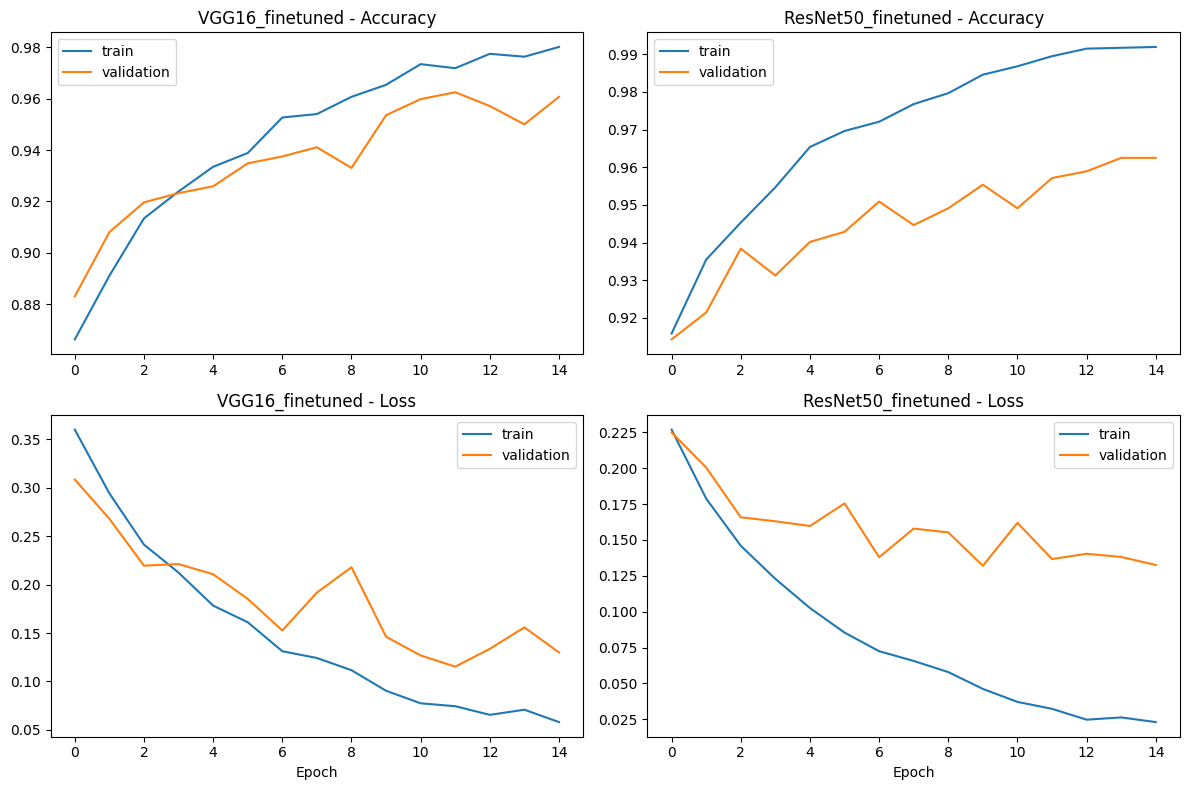

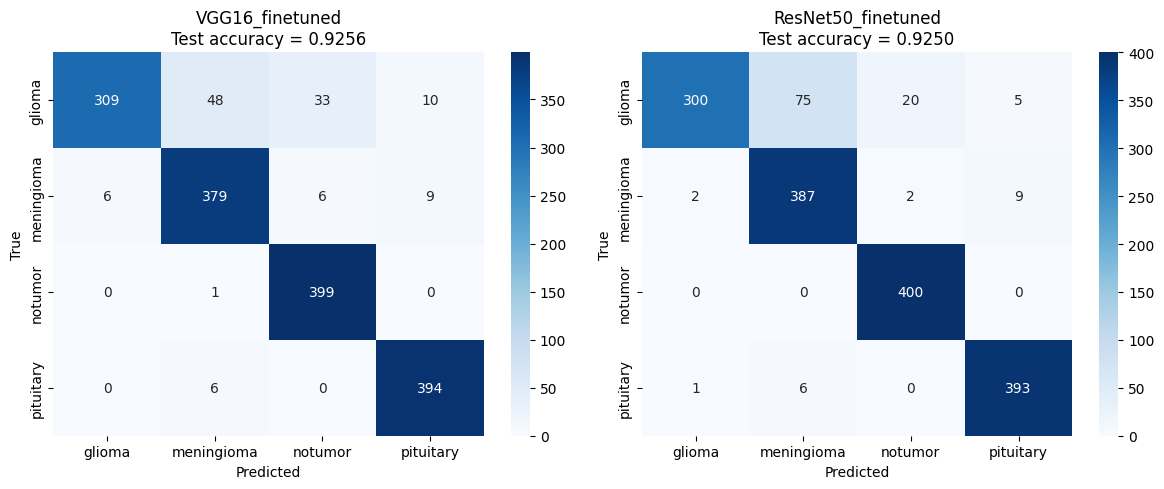

In [13]:
# ===== Step 14: Training curves and confusion matrices of the fine-tuned models =====
ft_names = ["VGG16_finetuned", "ResNet50_finetuned"]     # the two fine-tuned models

fig, axes = plt.subplots(2, 2, figsize=(12, 8))          # top row: accuracy, bottom row: loss
for col, name in enumerate(ft_names):                    # one column per model
    h = histories[name]                                  # training history of this model
    axes[0][col].plot(h["accuracy"], label="train")      # training accuracy
    axes[0][col].plot(h["val_accuracy"], label="validation")  # validation accuracy
    axes[0][col].set_title(f"{name} - Accuracy")         # title
    axes[0][col].legend()                                # show legend
    axes[1][col].plot(h["loss"], label="train")          # training loss
    axes[1][col].plot(h["val_loss"], label="validation") # validation loss
    axes[1][col].set_title(f"{name} - Loss")             # title
    axes[1][col].legend()                                # show legend
    axes[1][col].set_xlabel("Epoch")                     # x-axis label
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_curves_finetuned.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5))          # one confusion matrix per fine-tuned model
for ax, name in zip(axes, ft_names):                     # loop over the two models
    cm = confusion_matrix(y_test, predictions[name])     # confusion matrix (rows = true, columns = predicted)
    acc = np.trace(cm) / cm.sum()                        # accuracy = correct predictions / all predictions
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)  # draw it as a heatmap
    ax.set_title(f"{name}\nTest accuracy = {acc:.4f}")   # title with the accuracy
    ax.set_xlabel("Predicted")                           # x-axis label
    ax.set_ylabel("True")                                # y-axis label
plt.tight_layout()                                       # fix spacing
plt.savefig(f"{OUT_DIR}/fig_confusion_finetuned.png", dpi=200, bbox_inches="tight")  # save the figure for the report
plt.show()                                               # display the confusion matrices